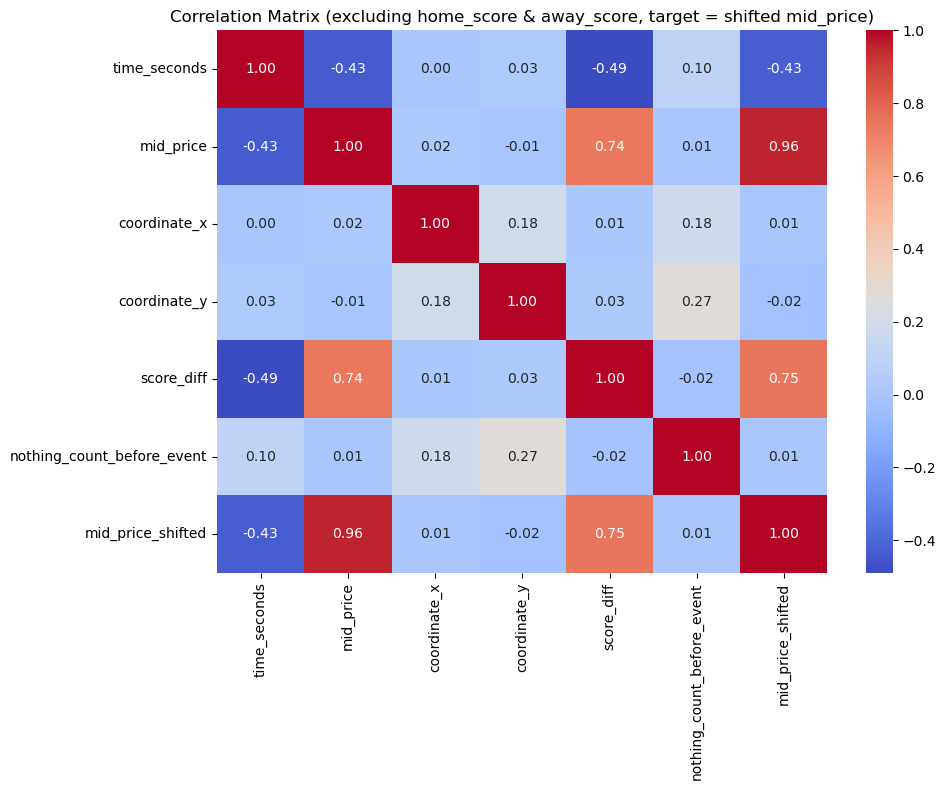

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load your modified CSV
df = pd.read_csv("data_modified.csv")

# Shift mid_price by 1 to represent tomorrow's price
df["mid_price_shifted"] = df["mid_price"].shift(-1)

# Drop home_score and away_score from correlation
corr_df = df.drop(columns=["home_score", "away_score"])

# Select only numeric columns for correlation
numeric_df = corr_df.select_dtypes(include=["int64", "float64"])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Save correlation matrix to CSV (optional)
corr_matrix.to_csv("correlation_matrix.csv")

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation Matrix (excluding home_score & away_score, target = shifted mid_price)")
plt.tight_layout()
plt.show()


In [5]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Load modified data
df = pd.read_csv("data_modified.csv")

# Target: next day's mid_price
df["mid_price_shifted"] = df["mid_price"].shift(-1)

# Drop NaN (last row)
df = df.dropna(subset=["mid_price_shifted"])

# Features and target
X = df.drop(columns=["mid_price", "mid_price_shifted", "home_score", "away_score"])
y = df["mid_price_shifted"]

# One-hot encode categoricals
categorical_cols = ["event_type", "shot_type", "rebound_type", "home_away"]
X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

# Get feature importances
feature_importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Save to CSV
feature_importances.to_csv("feature_importances.csv")

print("Top 10 most important features for predicting tomorrow's mid_price:")
print(feature_importances.head(10))


Top 10 most important features for predicting tomorrow's mid_price:
time_seconds                  0.532035
score_diff                    0.416693
nothing_count_before_event    0.016119
coordinate_y                  0.004956
coordinate_x                  0.004295
event_type_SUBSTITUTION       0.002941
home_away_away                0.002386
home_away_home                0.002335
shot_type_FREE_THROW          0.002017
rebound_type_DEFENSIVE        0.001546
dtype: float64


In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Regressors
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# -----------------------
# Load Data
# -----------------------
try:
    df = pd.read_csv("data_modified.csv")
except FileNotFoundError:
    print("Warning: 'data_modified.csv' not found. Using dummy data for demonstration.")
    data = {
        'mid_price': np.random.rand(1000) * 100,
        'home_score': np.random.randint(0, 5, 1000),
        'away_score': np.random.randint(0, 5, 1000),
        'feature1': np.random.rand(1000),
        'feature2': np.random.rand(1000),
        'event_type': np.random.choice(['A', 'B', 'C'], 1000),
        'shot_type': np.random.choice(['X', 'Y'], 1000),
        'rebound_type': np.random.choice(['P', 'Q', 'R'], 1000),
        'home_away': np.random.choice(['Home', 'Away'], 1000),
    }
    df = pd.DataFrame(data)

# -----------------------
# Prepare Features & Target
# -----------------------

# Shift target: predict tomorrow's mid_price
df["mid_price_shifted"] = df["mid_price"].shift(-1)

# Drop NaN (last row has no "tomorrow" price)
df = df.dropna(subset=["mid_price_shifted"])

# Features: drop raw mid_price, shifted target, and unused scores
X = df.drop(columns=["mid_price", "mid_price_shifted", "home_score", "away_score"])
y = df["mid_price_shifted"]

# One-hot encode categoricals
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -----------------------
# Helper: Evaluate Models
# -----------------------
results = {}

def evaluate_model(model, name):
    """Fit a model, evaluate, and store metrics."""
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    print(f"\n--- {name} ---")
    print(f"R²:   {r2:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")

    results[name] = {"R²": r2, "MAE": mae, "RMSE": rmse}
    return r2, mae, rmse

# -----------------------
# Train & Evaluate Models
# -----------------------

# Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
evaluate_model(rf, "Random Forest")

# HistGradientBoosting
hgb = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=2, random_state=42)
evaluate_model(hgb, "HistGradientBoosting")

# XGBoost
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=2, random_state=42)
evaluate_model(xgb, "XGBoost")

# LightGBM
lgb = LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=-1, random_state=42)
evaluate_model(lgb, "LightGBM")

# CatBoost (silent)
cat = CatBoostRegressor(iterations=200, learning_rate=0.05, depth=2, random_state=42, verbose=0)
evaluate_model(cat, "CatBoost")

# -----------------------
# CatBoost with Early Stopping
# -----------------------
# Split training into train + validation for early stopping
X_train_cb, X_valid_cb, y_train_cb, y_valid_cb = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42
)

cat_es = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=2,
    random_state=42,
    verbose=100
)

cat_es.fit(
    X_train_cb, y_train_cb,
    eval_set=(X_valid_cb, y_valid_cb),
    early_stopping_rounds=50
)

# Evaluate
preds = cat_es.predict(X_test)
r2 = r2_score(y_test, preds)
mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))

print(f"\n--- CatBoost (Early Stopping) ---")
print(f"R²:   {r2:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

results["CatBoost (Early Stopping)"] = {"R²": r2, "MAE": mae, "RMSE": rmse}

# -----------------------
# Save Results
# -----------------------
results_df = pd.DataFrame(results).T
print("\nModel Comparison:\n", results_df)
results_df.to_csv("model_comparison.csv")



--- Random Forest ---
R²:   0.7751
MAE:  4.9492
RMSE: 8.3424

--- HistGradientBoosting ---
R²:   0.8405
MAE:  4.4723
RMSE: 7.0253

--- XGBoost ---
R²:   0.8475
MAE:  4.3951
RMSE: 6.8706
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000385 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 375
[LightGBM] [Info] Number of data points in the train set: 980, number of used features: 21
[LightGBM] [Info] Start training from score 76.360234

--- LightGBM ---
R²:   0.7723
MAE:  5.0922
RMSE: 8.3936

--- CatBoost ---
R²:   0.8429
MAE:  4.5960
RMSE: 6.9715
0:	learn: 18.1590932	test: 18.8416530	best: 18.8416530 (0)	total: 93us	remaining: 46.7ms
100:	learn: 7.5861356	test: 6.5886263	best: 6.5886263 (100)	total: 6.8ms	remaining: 26.9ms
200:	learn: 7.1422923	test: 6.4885479	best: 6.4513429 (187)	total: 13.7ms	remaining: 20.4ms
Stopped by overfitting detector  (50 iterations wait)

bestTest = 6.451342921
bestItera

In [45]:
# Mappings
home_away_map = {"home": 0, "away": 1, "unknown": 2}
event_type_map = {
    "SCORE": 0, "UNKNOWN": 1, "END_GAME": 2, "REBOUND": 3, "TIMEOUT": 4, "FOUL": 5,
    "END_PERIOD": 6, "BLOCK": 7, "JUMP_BALL": 8, "STEAL": 9, "TURNOVER": 10,
    "SUBSTITUTION": 11, "NOTHING": 12, "MISSED": 13, "START_PERIOD": 14
}
shot_type_map = {"FREE_THROW": 0, "THREE_POINT": 1, "LAYUP": 2, "DUNK": 3, "TWO_POINT": 4, None: 5}
rebound_type_map = {"OFFENSIVE": 0, "DEFENSIVE": 1, None: 2}

def encode_row_to_number(row):
    """Encodes a row dict into a list of integers/floats for compact storage."""
    return [
        home_away_map.get(row["home_away"], 2),
        event_type_map.get(row["event_type"], 1),
        shot_type_map.get(row["shot_type"], 5),
        rebound_type_map.get(row["rebound_type"], 2),
        int(row.get("coordinate_x", 0) * 100),  # scale floats to int
        int(row.get("coordinate_y", 0) * 100),
        int(row.get("time_seconds", 0)),
        int(row.get("home_score", 0)),
        int(row.get("away_score", 0)),
        int(row.get("score_diff", 0)),
        int(row.get("nothing_count_before_event", 0)),
        int(row.get("mid_price", 0) * 100)  # scale price
    ]

def decode_number_to_row(num_list):
    """Decodes list of numbers back to feature dict for training."""
    return {
        "home_away": num_list[0],
        "event_type": num_list[1],
        "shot_type": num_list[2],
        "rebound_type": num_list[3],
        "x": num_list[4] / 100.0,
        "y": num_list[5] / 100.0,
        "time_seconds": float(num_list[6]),
        "home_score": float(num_list[7]),
        "away_score": float(num_list[8]),
        "score_diff": float(num_list[9]),
        "nothing_count_before_event": float(num_list[10]),
        "mid_price": num_list[11] / 100.0
    }

import pandas as pd

def encode_csv(df):
    encoded_list = []
    for _, row in df.iterrows():
        encoded_list.append(encode_row_to_number(row))
    return encoded_list

df = pd.read_csv("data_modified.csv")
encoded_numbers = encode_csv(df)
print(encoded_numbers)


[[0, 11, 5, 2, 0, 0, 1888, 29, 34, -5, 7, 4098], [0, 0, 4, 2, 400, 1000, 1886, 31, 34, -3, 0, 4092], [1, 13, 4, 2, 2100, 100, 1871, 31, 34, -3, 6, 4587], [1, 3, 5, 0, 0, 0, 1871, 31, 34, -3, 0, 4587], [1, 0, 4, 2, 2700, 0, 1869, 31, 36, -5, 0, 4576], [0, 13, 4, 2, 2900, 400, 1850, 31, 36, -5, 14, 4069], [0, 3, 5, 0, 0, 0, 1850, 31, 36, -5, 0, 4069], [0, 0, 4, 2, 2700, 100, 1848, 33, 36, -3, 1, 4082], [1, 0, 3, 2, 2500, 0, 1828, 33, 38, -5, 16, 4568], [0, 9, 5, 2, 0, 0, 1820, 33, 38, -5, 6, 4097], [0, 11, 5, 2, 0, 0, 1820, 33, 38, -5, 0, 4097], [0, 3, 5, 1, 0, 0, 1794, 33, 38, -5, 18, 4054], [0, 0, 2, 2, 2500, 100, 1790, 35, 38, -3, 3, 4058], [2, 1, 5, 2, 0, 0, 1779, 35, 38, -3, 10, 4561], [1, 11, 5, 2, 0, 0, 1779, 35, 38, -3, 0, 4561], [1, 0, 2, 2, 2500, 100, 1773, 35, 40, -5, 5, 4556], [1, 5, 5, 2, 0, 0, 1756, 35, 40, -5, 13, 4036], [0, 0, 0, 2, 2500, 0, 1756, 36, 40, -4, 0, 4036], [0, 13, 0, 2, 2500, 0, 1756, 36, 40, -4, 0, 4036], [1, 3, 5, 1, 0, 0, 1756, 36, 40, -4, 0, 4036], [1, 0,